  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Wine Quality Dataset:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4   

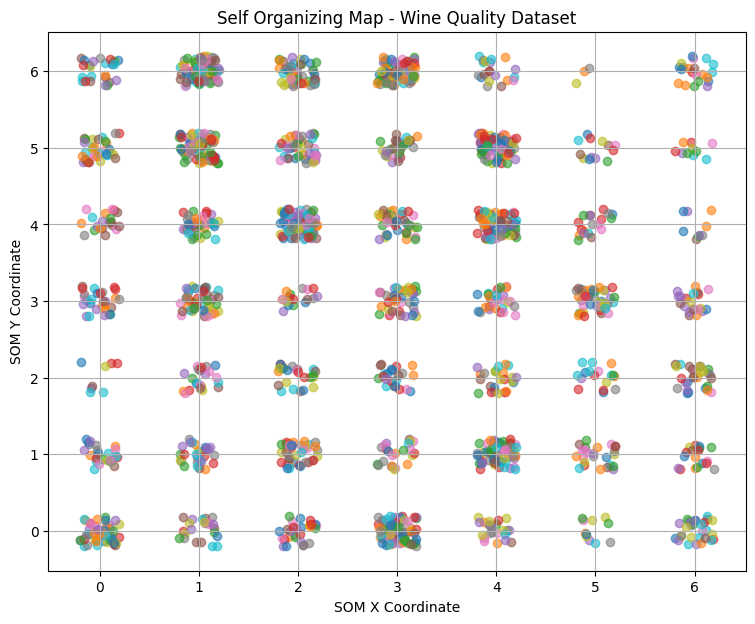

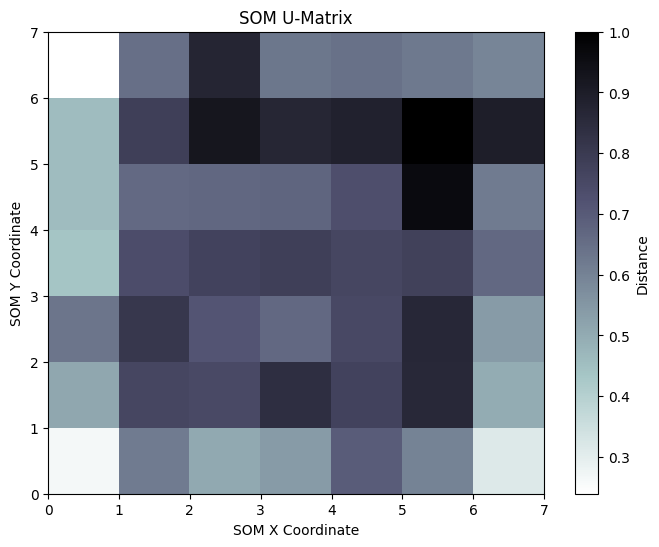


Clustered dataset saved successfully!


In [1]:

!pip install minisom -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.preprocessing import MinMaxScaler

# Read Wine Quality Dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
data = pd.read_csv(url, sep=';')

print("Wine Quality Dataset:")
print(data.head())
print("\nDataset Shape:", data.shape)

# Remove target column for unsupervised learning
X = data.drop("quality", axis=1)

# Normalize data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Create Self Organizing Map
som = MiniSom(
    x=7, y=7,
    input_len=X_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize and train SOM
som.random_weights_init(X_scaled)
som.train_random(X_scaled, 1000)

print("\nSOM Training Completed Successfully!")

# Assign clusters
clusters = []
for sample in X_scaled:
    winner = som.winner(sample)
    clusters.append(winner[0] * 7 + winner[1])

data["SOM_Cluster"] = clusters

print("\nClustered Dataset:")
print(data.head(10))

print("\nTotal SOM Clusters:", len(set(clusters)))

# SOM Cluster Visualization
plt.figure(figsize=(9, 7))

for i, sample in enumerate(X_scaled):
    winner = som.winner(sample)
    plt.scatter(
        winner[0] + np.random.uniform(-0.2, 0.2),
        winner[1] + np.random.uniform(-0.2, 0.2),
        alpha=0.6
    )

plt.title("Self Organizing Map - Wine Quality Dataset")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")
plt.grid()
plt.show()

# U-Matrix Visualization
plt.figure(figsize=(8, 6))
plt.pcolor(som.distance_map().T, cmap="bone_r")
plt.colorbar(label="Distance")
plt.title("SOM U-Matrix")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")
plt.show()

# Save clustered dataset
data.to_csv("SOM_Wine_Clustered.csv", index=False)

print("\nClustered dataset saved successfully!")